In [61]:
import P04_Parser
from igor2 import binarywave
import numpy as np
import matplotlib.pyplot as plt
import re
import hyperspy.api as hs
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

def load_ibw_swept_as_kmap(file):
    """Swept (2D) .ibw cut -> Kmap with 3 identical theta_y slices, so P04_Parser plotting works."""
    wave = binarywave.load(file)["wave"]
    data = np.array(wave["wData"], dtype=float)     # (energy, angle)
    sfa = wave["wave_header"]["sfA"]
    sfb = wave["wave_header"]["sfB"]
    energy = sfb[0] + sfa[0] * np.arange(data.shape[0])
    theta = sfb[1] + sfa[1] * np.arange(data.shape[1])
    data_map = np.repeat(data[:, :, np.newaxis], 3, axis=2)
    return P04_Parser.Kmap(data_map, energy, theta, np.array([-1, 0, 1]))

In [62]:
import P04_Parser

data = load_ibw_swept_as_kmap(
    r"T:\Beamtimes\MaxIV\Oct_26\raw\FeSi_2B_49eV_LV_temp_series\FeSi_2B_hv_49_LV_GX_20K_0001Swept.ibw"
)


roi = data.get_rois_in_grid(plot=False)[0]
asd = data.get_EDC_inside(roi)



In [63]:
import os
import re

file_dir = r"T:\Beamtimes\MaxIV\Oct_26\raw\FeSi_2B_49eV_LV_temp_series"
files = os.listdir(file_dir)

files_names_fesi = [f for f in files if f.endswith(".ibw") and "testing" not in f and f.startswith("TaFoil")]

# Sort by temperature, with each "down" scan right after its "up" scan
def sort_key(f):
    T = float(re.search(r"_(\d+(?:\.\d+)?)K", f).group(1))
    return (T, "down" in f.lower())

files_names_fesi = sorted(files_names_fesi, key=sort_key)
files = [os.path.join(file_dir, f) for f in files_names_fesi]

def temp_from_filename(f):
    return str(re.search(r"_(\d+(?:\.\d+)?)K", f).group(1)) + "K" + (" down" if "down" in f.lower() else "")

labels = {f: temp_from_filename(f) for f in files_names_fesi} #[20:-14] for FeSi and [19:-17] for TaFoil
labels

{'TaFoil_hv_49_LV_GX_20K_0001Swept.ibw': '20K',
 'TaFoil_hv_49_LV_GX_20K_0002Swept_Ta.ibw': '20K',
 'TaFoil_hv_49_LV_GX_20K_down_0001Swept_Ta.ibw': '20K down',
 'TaFoil_hv_49_LV_GX_60K_down_0001Swept_Ta.ibw': '60K down',
 'TaFoil_hv_49_LV_GX_100K_0001Swept_Ta.ibw': '100K',
 'TaFoil_hv_49_LV_GX_100K_down_0001Swept_Ta.ibw': '100K down',
 'TaFoil_hv_49_LV_GX_200K_0001Swept_Ta.ibw': '200K'}

In [ ]:
# %matplotlib qt
for f in files:
    data = load_ibw_swept_as_kmap(f)

    edc = data.get_EDC_inside(roi = hs.roi.CircleROI(cx=0, cy=0, r=15))
    span = hs.roi.SpanROI(left=0, right=100)

    fermi, popt, pcov, kinetic_energies, signal_data = data.fit_fermi_energy(edc = edc, span = span, fix_temp=sort_key(f)[0], plot=False, print_verbose_output=True, return_fit_params=True)
    print(np.sqrt(pcov[3, 3]))

0.00012357135007220638
4.4161112676138466e-05
4.760896926973189e-05
6.0861419113574845e-05
8.999603370549193e-05
8.070020429475112e-05
0.00011011125416219136


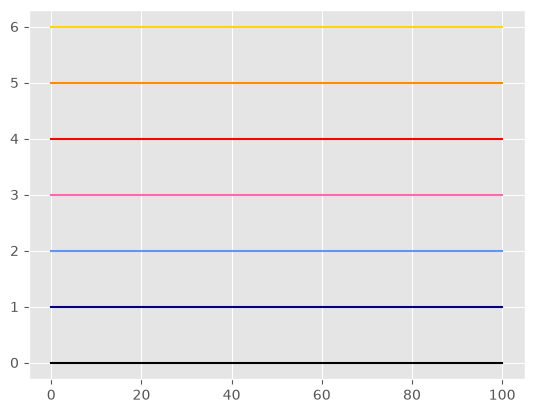

In [106]:
colors = ["black", "navy", "cornflowerblue", "hotpink", "red", "darkorange", "gold"]

for i in range(len(colors)):
    plt.plot(np.linspace(0, 100, 100), np.ones(100)*i, color=colors[i])

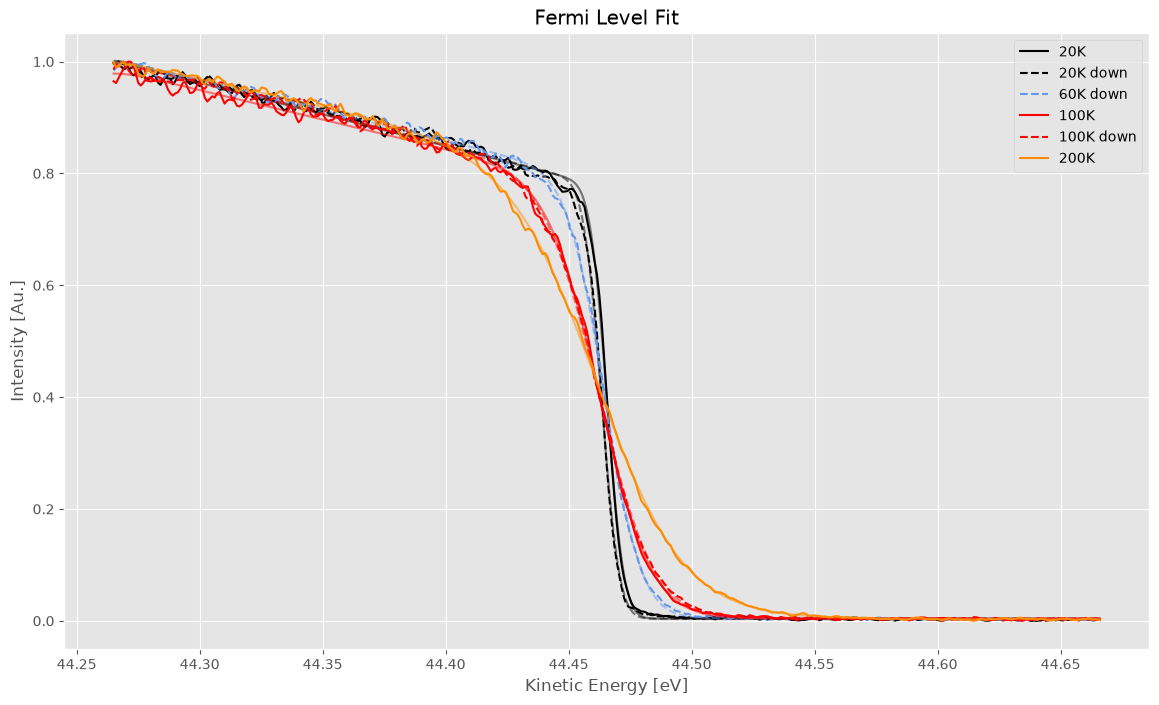

In [ ]:
from scipy.ndimage import gaussian_filter1d, zoom
from P04_Parser.util_funcs import (
    fit_2d_polynomial,
    evaluate_2d_polynomial,
    fermi_dirac,
    fermi_lin,
    angle_to_kx_deflector,
    angle_to_ky_deflector,
)
from scipy.optimize import curve_fit

cmap = mpl.colormaps["plasma"]
norm = mpl.colors.Normalize(vmin=1, vmax=5)
temp_to_index = {20: 0, 40: 1, 60: 2, 100: 4, 200: 5}


def line_style(file):
    name = Path(file).name
    T = temp_to_index[int(re.search(r"_(\d+(?:\.\d+)?)K", name).group(1))]
    return dict(
        color=colors[T],
        linestyle="--" if "down" in name.lower() else "-",
    )

fig, ax = plt.subplots(figsize=(14, 8))


fermi_levels = []

for f in files[1:]:
    fix_temp=sort_key(f)[0]

    data = load_ibw_swept_as_kmap(f)

    edc = data.get_EDC_inside(roi = hs.roi.CircleROI(cx=0, cy=0, r=15))
    span = hs.roi.SpanROI(left=-100, right=150)

    sig = span(edc)

    len_kin_en = sig.axes_manager[0].size
    offset_kin_en = sig.axes_manager[0].offset
    scale_kin_en = sig.axes_manager[0].scale

    kinetic_energies = np.linspace(
        44.265, offset_kin_en + scale_kin_en * len_kin_en, len_kin_en
    )

    intensity_data = sig.data
    
    intensity_data = (intensity_data - np.min(intensity_data)) / (np.max(intensity_data) - np.min(intensity_data))

    kinetic_energies, intensity_data

    def gauss_fermi_lin_fixed_temp(x, Gnd, Scale, Lin, Ef, sigma):
        kT = fix_temp * 8.6173303e-5

        return gaussian_filter1d(fermi_lin(x, Gnd, Scale, Lin, Ef, kT), sigma=sigma)

    fit_guess = (
                intensity_data[-1],
                intensity_data[0],
                intensity_data[1] - intensity_data[0],
                kinetic_energies[len(kinetic_energies) // 2],
                10,
    )
    fit_func = gauss_fermi_lin_fixed_temp
    bounds = (
        (0, 0, -np.inf, -np.inf, 0),
        (np.inf, np.inf, np.inf, np.inf, np.inf),
    )

    popt, pcov = curve_fit(
        fit_func, kinetic_energies, intensity_data, p0=fit_guess, bounds=bounds, absolute_sigma=False
    )



    # plt.figure()
    plt.plot(kinetic_energies, intensity_data,
            label=labels[Path(f).name],
            **line_style(f),)
    kin_en_highres = np.linspace(
        kinetic_energies[0], kinetic_energies[-1], 1000
    )

    ## The sigma broadening in gaussian_filter1d works in pixel by pixel, so when we want to plot higher
    ## resolution, eg 1000 datapoints here, we need to scale up the sigma acordingly.
    plt.plot(
        kin_en_highres,
        fit_func(
            kin_en_highres, *popt[:-1], popt[-1] * 1000 / len(kinetic_energies)
        ),
        # label=labels[Path(f).name] + "fit",
        alpha=0.5,
        **line_style(f),
    )
    fermi_levels.append([popt[3], np.sqrt(pcov[3, 3]), labels[Path(f).name]])
    # plt.errorbar(popt[3], 1, xerr=pcov[3, 3] ** 0.5, fmt='.', color=line_style(f)["color"])
    plt.xlabel("Kinetic Energy [eV]")
    plt.ylabel("Intensity [Au.]")
    plt.title(
        f"Fermi Level Fit"
    )
    plt.legend()

In [ ]:
popt
x, Gnd, Scale, Lin, Ef, sigma

array([ 3.06930764e-03,  4.37811679e+01, -9.66492971e-01,  4.44630036e+01,
        5.68560127e+00])

In [67]:
np.save("fermi_levels.npy", np.array(fermi_levels))

Text(0, 0.5, 'Fermi level (eV)')

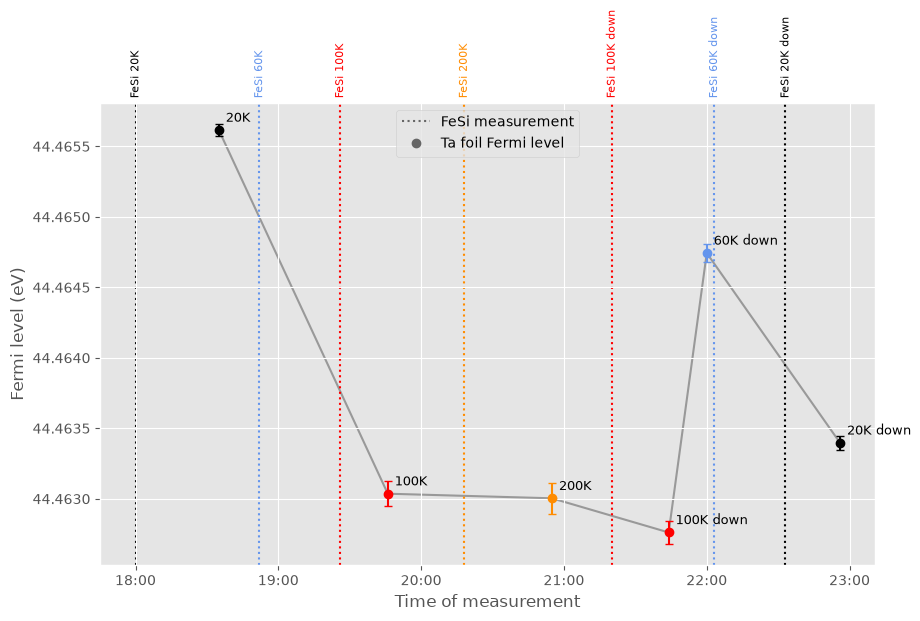

In [112]:
# Ta foil scan times from the measurement log (HH.MM)
measurement_time = {
    "20K":       18.35, # both 20K scans (0001 and 0002) were taken at 18.35
    "100K":      19.46,
    "200K":      20.55,
    "100K down": 21.44,
    "60K down":  22.00,
    "20K down":  22.56,
}

# FeSi scan times from the measurement log (HH.MM)
fesi_measurement_time = {
    "20K":       18.00,
    "60K":       18.52,
    "100K":      19.26,
    "200K":      20.18,
    "100K down": 21.20,
    "60K down":  22.03,
    "20K down":  22.33,
}

def hhmm_to_hours(t):
    h = int(t)
    return h + round((t - h) * 100) / 60

def temp_color(lab):
    return colors[temp_to_index[int(lab.split("K")[0])]]

label_to_file = {labels[Path(f).name]: f for f in files[1:]}

rows = sorted(
    (hhmm_to_hours(measurement_time[lab]), e, s, lab) for e, s, lab in fermi_levels
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot([r[0] for r in rows], [r[1] for r in rows], "-", color="0.6", zorder=0)
for t, e, s, lab in rows:
    ax.errorbar(t, e, yerr=s, fmt="o", capsize=3, color=line_style(label_to_file[lab])["color"])
    ax.annotate(lab, (t, e), textcoords="offset points", xytext=(5, 6), fontsize=9)

# FeSi scans as vertical lines, labelled along the top of the axes
for lab, t in fesi_measurement_time.items():
    t = hhmm_to_hours(t)
    ax.axvline(t, color=temp_color(lab), linestyle=":", lw=1.5, zorder=0)
    ax.text(t, 1.01, f"FeSi {lab}", transform=ax.get_xaxis_transform(),
            rotation=90, ha="center", va="bottom", fontsize=8, color=temp_color(lab))
ax.plot([], [], ":", color="0.4", label="FeSi measurement")
ax.plot([], [], "o", color="0.4", label="Ta foil Fermi level")
ax.legend(loc="best")

ax.xaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda h, _: f"{int(h):02d}:{round(h % 1 * 60):02d}")
)
ax.ticklabel_format(axis="y", useOffset=False)
ax.set_xlabel("Time of measurement")
ax.set_ylabel("Fermi level (eV)")


In [69]:
plt.style.use("ggplot")

# FeSi plot adjusted for fermi level shifts

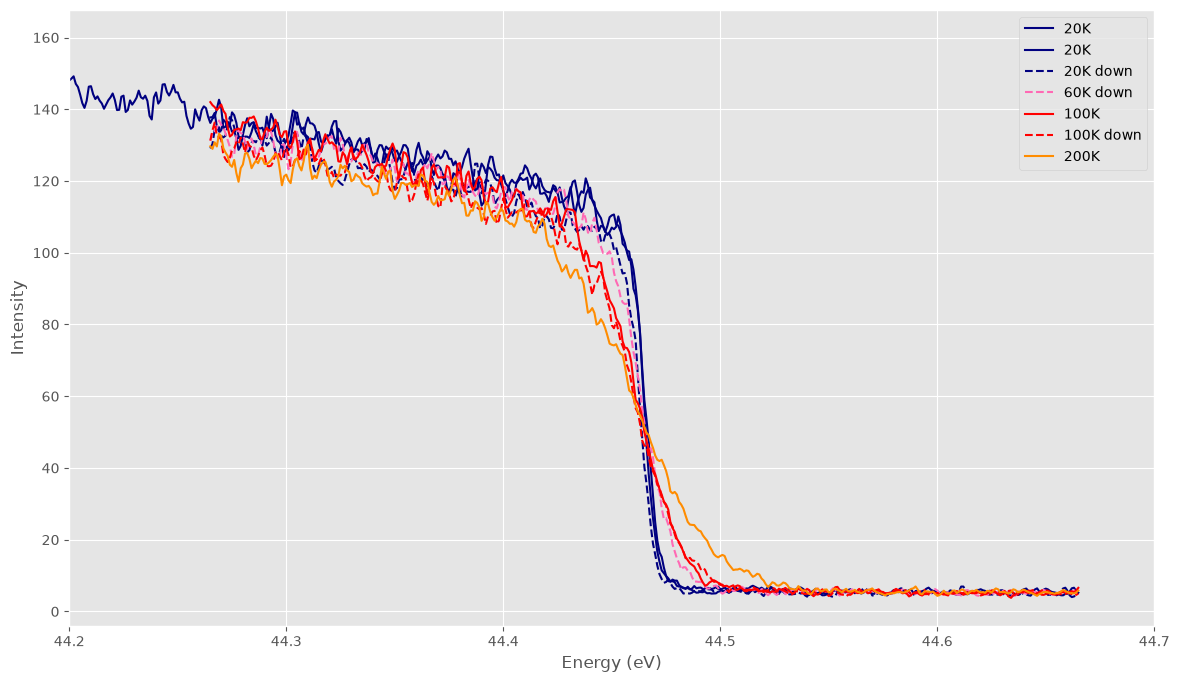

In [113]:

import os
import re

file_dir = r"T:\Beamtimes\MaxIV\Oct_26\raw\FeSi_2B_49eV_LV_temp_series"
files = os.listdir(file_dir)

files_names_fesi = [f for f in files if f.endswith(".ibw") and "testing" not in f and f.startswith("TaFoil")]

# Sort by temperature, with each "down" scan right after its "up" scan
def sort_key(f):
    T = float(re.search(r"_(\d+(?:\.\d+)?)K", f).group(1))
    return (T, "down" in f.lower())

files_names_fesi = sorted(files_names_fesi, key=sort_key)
files = [os.path.join(file_dir, f) for f in files_names_fesi]

def temp_from_filename(f):
    return str(re.search(r"_(\d+(?:\.\d+)?)K", f).group(1)) + "K" + (" down" if "down" in f.lower() else "")

labels = {f: temp_from_filename(f) for f in files_names_fesi} #[20:-14] for FeSi and [19:-17] for TaFoil
labels

# inferno colormap: 20 K -> min, 200 K -> max; "down" scans dashed
cmap = mpl.colormaps["plasma"]
norm = mpl.colors.Normalize(vmin=1, vmax=5)
temp_to_index = {20: 1, 40: 2, 60: 3, 100: 4, 200: 5}


def line_style(file):
    name = Path(file).name
    T = temp_to_index[int(re.search(r"_(\d+(?:\.\d+)?)K", name).group(1))]
    return dict(
        color=colors[T],
        linestyle="--" if "down" in name.lower() else "-",
    )

fig, ax = plt.subplots(figsize=(14, 8))

first_roi = None

for file in files:
    data = load_ibw_swept_as_kmap(file)

    if first_roi is None:
        first_roi = data.get_rois_in_grid(plot=False)[0]

    roi = hs.roi.CircleROI(
        cx=0,
        cy=0,
        r=2,
    )

    edc = data.get_EDC_inside(roi)
    energy_axis = edc.axes_manager[0].axis

    ax.plot(
        energy_axis,
        edc.data,
        label=labels[Path(file).name],
        **line_style(file),
    )

ax.set_xlim(44.2, 44.7)
ax.set_xlabel("Energy (eV)")
ax.set_ylabel("Intensity")
ax.legend()
plt.show()

# Interactive manual fermi level fixer

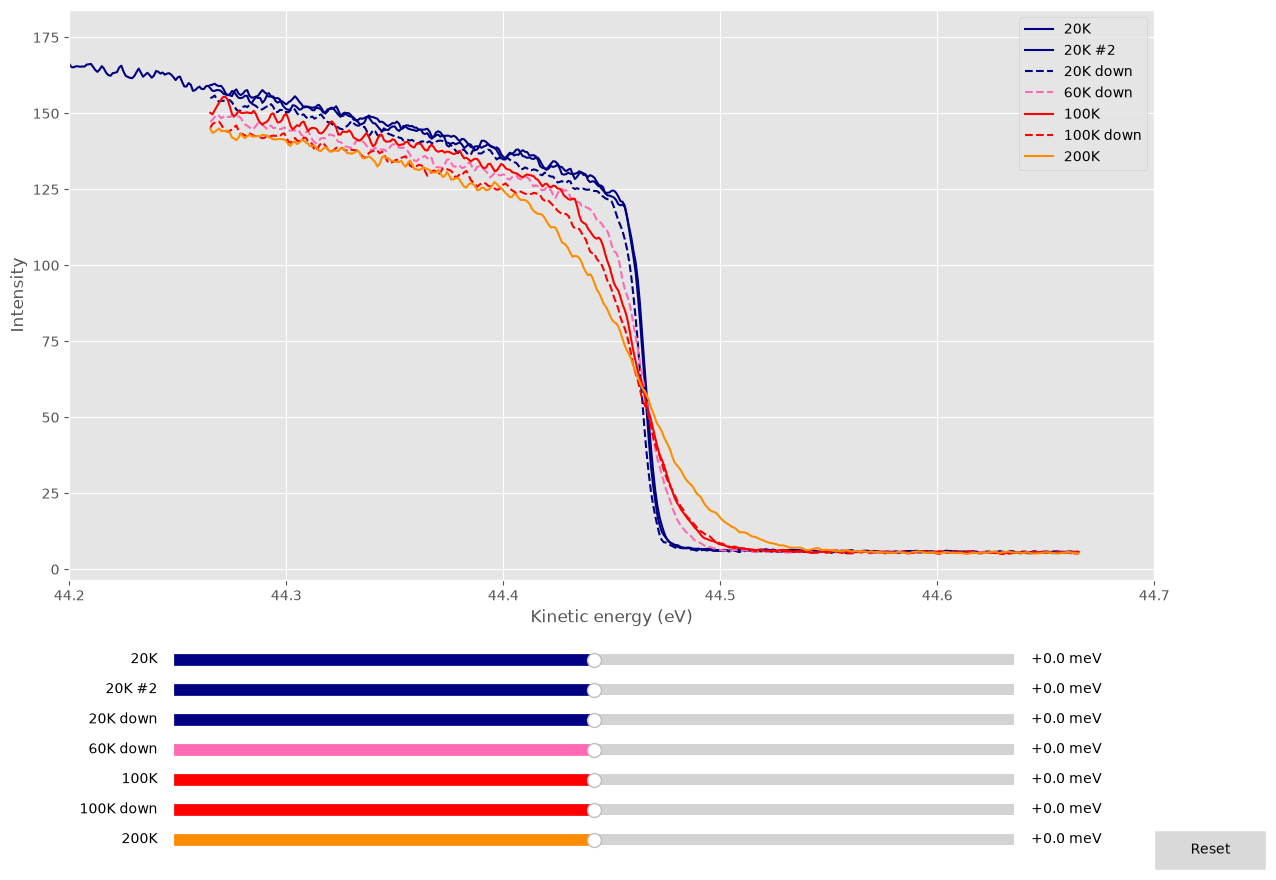

In [114]:
# %matplotlib qt
from matplotlib.widgets import Slider, Button

max_shift = 0.02  # eV, slider range is +-max_shift

edcs = []
for file in files:
    data = load_ibw_swept_as_kmap(file)
    edc = data.get_EDC_inside(hs.roi.CircleROI(cx=0, cy=0, r=15))
    edcs.append((file, edc.axes_manager[0].axis, edc.data))

# Two files share the "20K" label, so number duplicates to keep slider names unique
slider_labels = []
for file, _, _ in edcs:
    lab = labels[Path(file).name]
    n = sum(l == lab or l.startswith(lab + " #") for l in slider_labels)
    slider_labels.append(lab if n == 0 else f"{lab} #{n + 1}")

slider_height = 0.03
plot_bottom = 0.1 + slider_height * len(edcs)
fig, ax = plt.subplots(figsize=(14, 10))
fig.subplots_adjust(bottom=plot_bottom)

lines = []
for (file, energy, intensity), lab in zip(edcs, slider_labels):
    (line,) = ax.plot(energy, intensity, label=lab, **line_style(file))
    lines.append(line)

ax.set_xlim(44.2, 44.7)
ax.set_xlabel("Kinetic energy (eV)")
ax.set_ylabel("Intensity")
ax.legend()

sliders = []
for i, lab in enumerate(slider_labels):
    slider_ax = fig.add_axes([0.2, plot_bottom - 0.06 - slider_height * (i + 1), 0.6, slider_height * 0.7])
    slider = Slider(
        slider_ax, lab, -max_shift * 1e3, max_shift * 1e3, valinit=0, valstep=0.1,
        valfmt="%+.1f meV", color=line_style(edcs[i][0])["color"],
    )

    sliders.append(slider)

def update(_):
    for (_, energy, _), line, slider in zip(edcs, lines, sliders):
        line.set_xdata(energy + slider.val * 1e-3)
    fig.canvas.draw_idle()

for slider in sliders:
    slider.on_changed(update)

reset_ax = fig.add_axes([0.9, 0.02, 0.08, 0.04])
reset_button = Button(reset_ax, "Reset")
reset_button.on_clicked(lambda _: [s.reset() for s in sliders])

def get_shifts():
    """Current slider shift (eV) per curve, keyed by slider label."""
    return {lab: s.val for lab, s in zip(slider_labels, sliders)}

plt.show()

In [72]:
sadasd

NameError: name 'sadasd' is not defined

60K: no Ta foil fit, using mean E_F = 44.46376 eV


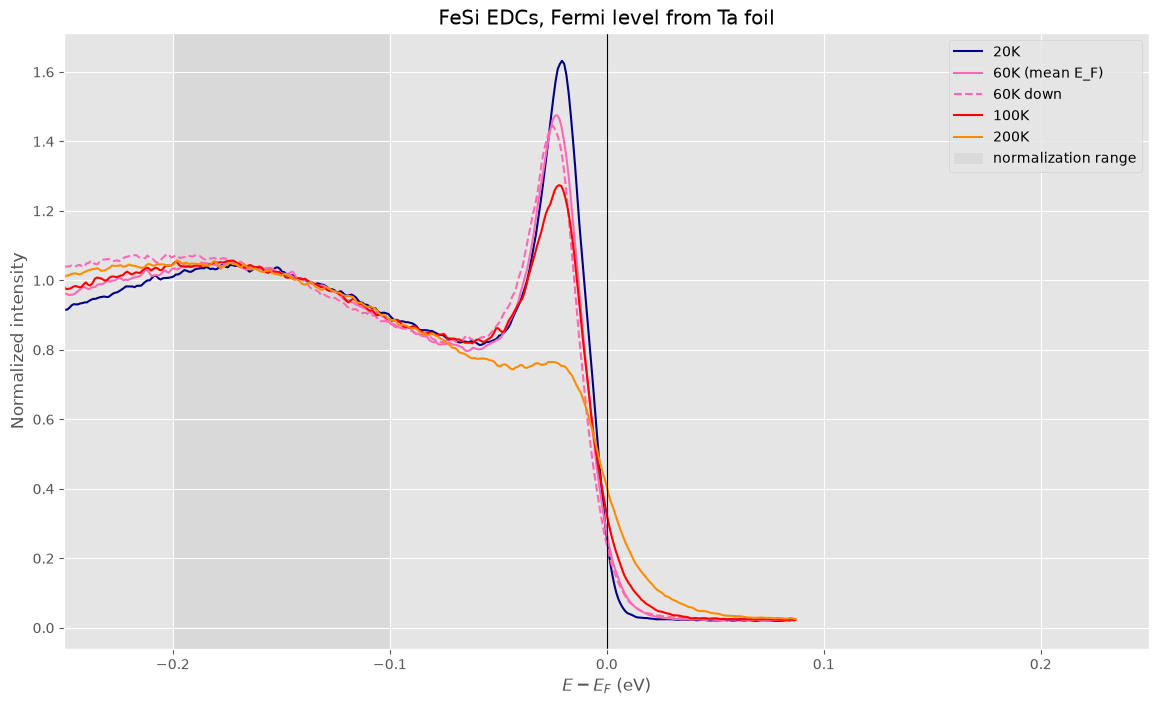

In [120]:
# FeSi EDCs on an E - E_F axis, with E_F taken from the Ta foil fit at the same temperature

keep = ["20K", "60K", "100K", "200K", "60K down"]
norm_range = (-0.2, -0.1)  # E - E_F (eV); each EDC is divided by its mean intensity in this window

fesi_names = sorted(
    [f for f in os.listdir(file_dir) if f.endswith(".ibw") and "testing" not in f and f.startswith("FeSi")],
    key=sort_key,
)
fesi_names = [f for f in fesi_names if temp_from_filename(f) in keep]
fesi_files = [os.path.join(file_dir, f) for f in fesi_names]

E_F_of = {lab: ef for ef, _, lab in fermi_levels}
# No Ta foil scan exists for 60K (up), so fall back to the mean of the fitted values
E_F_fallback = np.mean([ef for ef, _, _ in fermi_levels])

fig, ax = plt.subplots(figsize=(14, 8))

for file in fesi_files:
    lab = temp_from_filename(Path(file).name)
    E_F = E_F_of.get(lab, E_F_fallback)
    if lab not in E_F_of:
        print(f"{lab}: no Ta foil fit, using mean E_F = {E_F:.5f} eV")

    data = load_ibw_swept_as_kmap(file)
    edc = data.get_EDC_inside(hs.roi.CircleROI(cx=-np.pi/4.49, cy=0, r=2))

    energy = edc.axes_manager[0].axis - E_F
    in_range = (energy >= norm_range[0]) & (energy <= norm_range[1])
    intensity = edc.data / np.nanmean(edc.data[in_range])

    ax.plot(
        energy,
        intensity,
        label=lab + ("" if lab in E_F_of else " (mean E_F)"),
        **line_style(file),
    )

ax.axvspan(*norm_range, color="0.85", zorder=0, label="normalization range")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlim(-0.25, 0.25)
ax.set_xlabel(r"$E - E_F$ (eV)")
ax.set_ylabel("Normalized intensity")
ax.set_title("FeSi EDCs, Fermi level from Ta foil")
ax.legend()
plt.show()

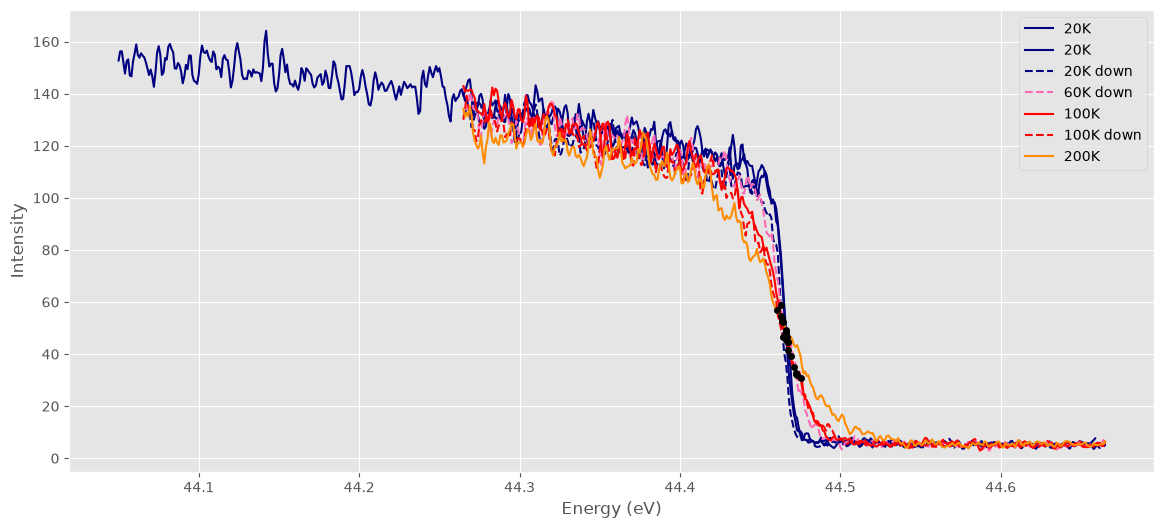

In [116]:
import numpy as np
import matplotlib.pyplot as plt
import hyperspy.api as hs
from pathlib import Path



# labels = {f: f[20:-14] for f in files_names_fesi}

fig, ax = plt.subplots(figsize=(14, 6))
curves = []

first_roi = None

for file in files:
    data = load_ibw_swept_as_kmap(file)

    if first_roi is None:
        first_roi = data.get_rois_in_grid(plot=False)[0]

    roi = hs.roi.CircleROI(
        cx=0,
        cy=0,
        r=1,
    )

    edc = data.get_EDC_inside(roi)
    energy = edc.axes_manager[0].axis
    intensity = np.asarray(edc.data).squeeze()
    label = labels[Path(file).name]

    curves.append((label, energy, intensity))
    ax.plot(energy, intensity, label=label, **line_style(file))

# Find intersections for every pair of curves
intersections = []

for i in range(len(curves)):
    for j in range(i + 1, len(curves)):
        label_i, energy_i, intensity_i = curves[i]
        label_j, energy_j, intensity_j = curves[j]

        # Use the overlapping energy range
        energy_min = max(energy_i.min(), energy_j.min())
        energy_max = min(energy_i.max(), energy_j.max())
        energy_common = np.linspace(energy_min, energy_max, 5000)

        intensity_i_common = np.interp(
            energy_common, energy_i, intensity_i
        )
        intensity_j_common = np.interp(
            energy_common, energy_j, intensity_j
        )

        difference = intensity_i_common - intensity_j_common
        crossing_indices = np.where(
            difference[:-1] * difference[1:] <= 0
        )[0]

        for index in crossing_indices:
            x1 = energy_common[index]
            x2 = energy_common[index + 1]
            y1 = difference[index]
            y2 = difference[index + 1]

            if y2 != y1:
                crossing_energy = x1 - y1 * (x2 - x1) / (y2 - y1)
                crossing_intensity = np.interp(
                    crossing_energy, energy_common, intensity_i_common
                )
                if crossing_intensity > 30 and crossing_intensity < 80: #400 and 1500 for FeSi and 30 and 80 for TaFoil
                    intersections.append(
                        [label_i, label_j, crossing_energy, crossing_intensity]
                    )

                    ax.plot(
                        crossing_energy,
                        crossing_intensity,
                        "ko",
                        markersize=4,
                    )

# for label_i, label_j, energy, intensity in intersections:
#     print(
#         f"{label_i} crosses {label_j} at "
#         f"energy={energy:.6g}, intensity={intensity:.6g}"
#     )

ax.set_xlabel("Energy (eV)")
ax.set_ylabel("Intensity")
ax.legend()
plt.show()

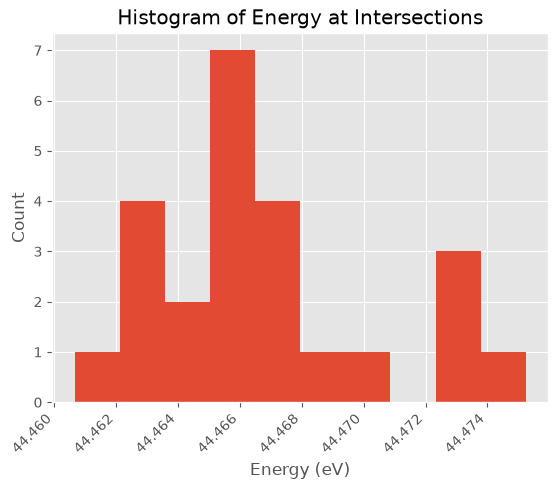

In [117]:
intersections_np = np.array(intersections)


plt.hist(intersections_np[:, 2].astype(float))
plt.xlabel("Energy (eV)")
plt.ylabel("Count")
plt.title("Histogram of Energy at Intersections")
plt.xticks(rotation=45, ha="right");


# E vs $\theta$

In [ ]:

data = load_ibw_swept_as_kmap(
    r"T:\Beamtimes\MaxIV\Oct_26\raw\FeSi_2B_49eV_LV_temp_series\FeSi_2B_hv_49_LV_GX_20K_0001Swept.ibw"
)


roi = data.get_rois_in_grid(plot=False)[0]
asd = data.get_EDC_inside(roi)



Non-down: [20.0, 20.0, 100.0, 200.0]
Down: [20.0, 60.0, 100.0]


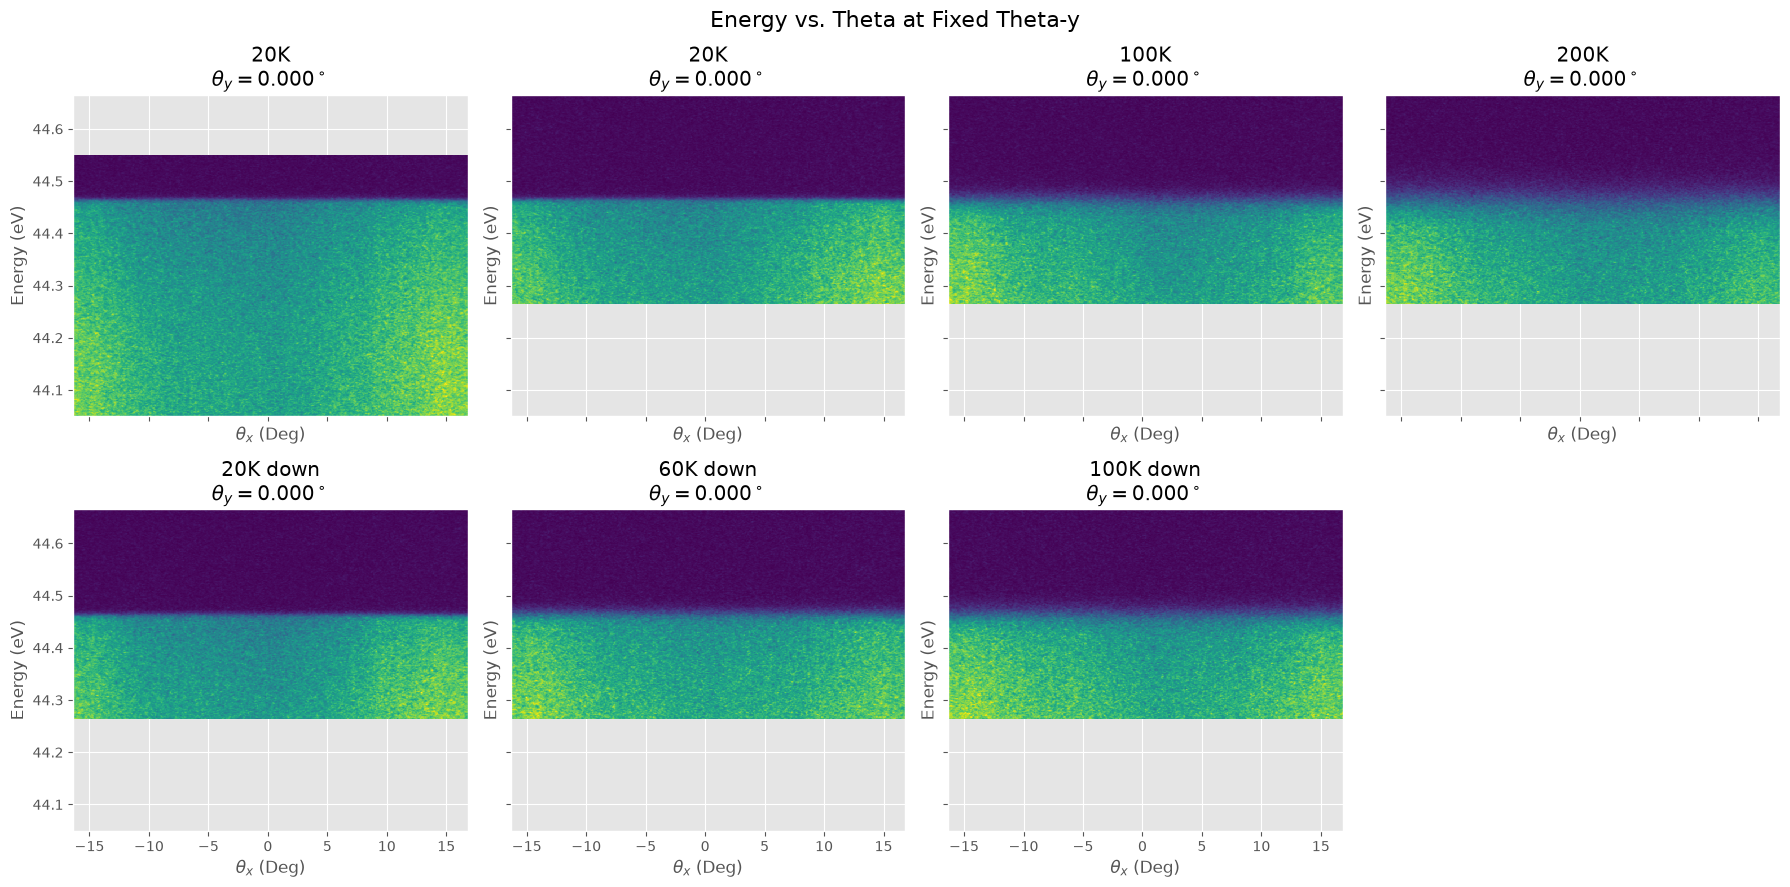

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

theta_y_value = 0

def temperature(file):
    match = re.search(r"(\d+(?:\.\d+)?)\s*K", Path(file).name)
    return float(match.group(1)) if match else float("inf")

def is_down(file):
    return "down" in Path(file).stem.lower()

non_down_files = sorted(
    [file for file in files if not is_down(file)],
    key=temperature,
)

down_files = sorted(
    [file for file in files if is_down(file)],
    key=temperature,
)

print("Non-down:", [temperature(file) for file in non_down_files])
print("Down:", [temperature(file) for file in down_files])

fig, axes = plt.subplots(
    2,
    4,
    figsize=(18, 9),
    sharex=True,
    sharey=True,
)

for row, selected_files in enumerate([non_down_files, down_files]):
    for column, file in enumerate(selected_files):
        data = load_ibw_swept_as_kmap(file)

        theta_y_index = np.argmin(
            np.abs(data.phi - theta_y_value)
        )

        ax = axes[row, column]

        ax.pcolormesh(
            data.theta,
            data.energy,
            data.data[:, :, theta_y_index],
            shading="auto",
        )

        ax.set_title(
            f"{labels[Path(file).name]}\n"
            rf"$\theta_y={data.phi[theta_y_index]:.3f}^\circ$"
        )
        ax.set_xlabel(r"$\theta_x$ (Deg)")
        ax.set_ylabel("Energy (eV)")

# Hide unused subplot, since there is no 200 K down scan
for column in range(len(down_files), 4):
    axes[1, column].set_visible(False)

fig.suptitle("Energy vs. Theta at Fixed Theta-y", fontsize=16)
fig.tight_layout()
plt.show()